In [7]:
# IMPORT LIBRARIES
import datetime
import yfinance as yf
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

In [8]:
# DOWNLOAD DATA
# Download NVDA historical 
endadate = datetime.datetime.now() - datetime.timedelta(days=1)
startdate = endadate - datetime.timedelta(days=365*5)
#nvda = yf.download('NVDA', start='2017-01-01', end='2023-01-01')
nvda = yf.download('NVDA', start=startdate, end=endadate)

[*********************100%***********************]  1 of 1 completed


In [9]:
# PREPARE DATA

df = nvda[['Close']]
df['Prediction'] = df['Close'].shift(-1)  # Shift 'Close' to create prediction target

# Remove last row as it has no prediction
df = df[:-1]

C:\Users\augustus\AppData\Local\Temp\ipykernel_8064\187401659.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Prediction'] = df['Close'].shift(-1)  # Shift 'Close' to create prediction target


In [10]:
# SPLIT DATA
# Split data into training and testing sets
X = df[['Close']]
y = df['Prediction']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Root Mean Squared Error: 2.23882831607754


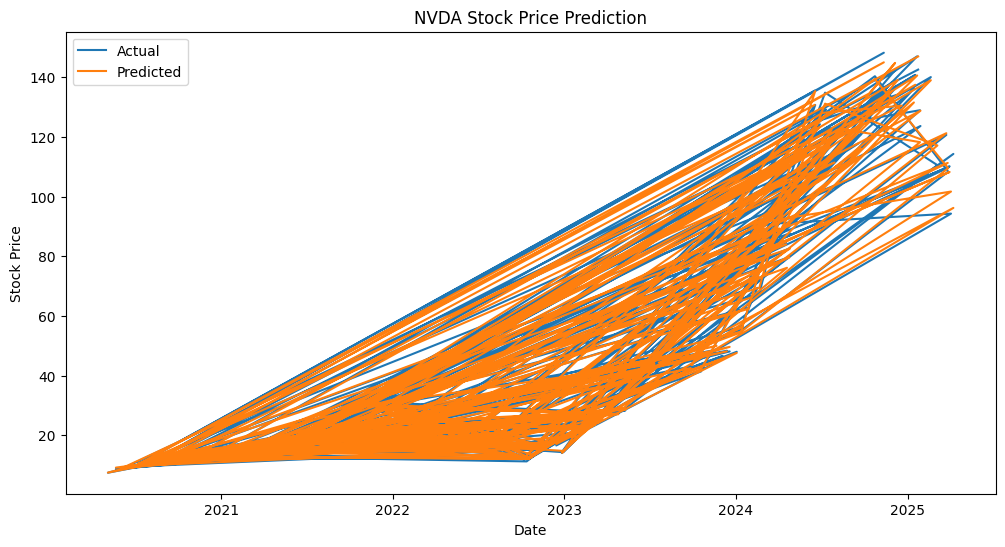

In [11]:
# TRAIN MODEL
# Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions on test set
y_pred = model.predict(X_test)

# Evaluate model
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print('Root Mean Squared Error:', rmse)

# Plot actual vs predicted stock prices
plt.figure(figsize=(12, 6))
plt.plot(y_test.index, y_test, label='Actual')
plt.plot(y_test.index, y_pred, label='Predicted')
plt.title('NVDA Stock Price Prediction')
plt.xlabel('Date')
plt.ylabel('Stock Price')
plt.legend()
plt.show()

In [12]:
# PREDICT 
# Predict future stock price (using the last available data point)
last_price = df['Close'].iloc[-1]
#future_prediction = model.predict(np.array([[last_price]]))[0]
future_prediction = model.predict(np.array(last_price).reshape(-1, 1))[0]

print('Predicted Stock Price for Tomorrow:', future_prediction)

Predicted Stock Price for Tomorrow: 104.39488603577549
